# 07 - Calibration Analysis

This notebook evaluates the probabilistic calibration of selected DenseNet-121 models.

Calibration is assessed before and after **temperature scaling** using Expected Calibration Error (ECE) and Brier score. Temperature scaling learns a single scalar temperature on the validation set and applies it to test logits without retraining the model.


In [1]:
import os
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import brier_score_loss

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# Publication settings
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['font.size'] = 11
mpl.rcParams['figure.dpi'] = 100
mpl.rcParams['savefig.dpi'] = 600
mpl.rcParams['savefig.bbox'] = 'tight'

Device: cuda


## 1. Configuration and Model Selection

This section defines the data locations, result directories, target pathologies, image size, batch size, and the models selected for calibration analysis.

The selected models include the clean baseline, noisy no-mitigation models, and several mitigation methods at 40% symmetric noise. Only model checkpoints that exist on disk are included in the analysis.


In [ ]:
RAW_DIR = os.path.join('..', 'data', 'raw')
PROCESSED_DIR = os.path.join('..', 'data', 'processed')
TEST_DIR = os.path.join('..', 'data', 'test')

BASELINE_MODEL_DIR = os.path.join('..', 'models')
NOISE_MODELS_DIR = os.path.join('..', 'models', 'noise_experiments')
MIT_MODELS_DIR = os.path.join('..', 'models', 'mitigation_experiments')

RESULTS_DIR = os.path.join('..', 'results')
CALIB_RESULTS_DIR = os.path.join('..', 'results', 'calibration')
FIGURES_DIR = os.path.join('..', 'results', 'figures')
os.makedirs(CALIB_RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

TARGET_PATHOLOGIES = [
    'Pleural Effusion',
    'Consolidation',
    'Cardiomegaly', 
    'Atelectasis', 
    'Edema'
]

BATCH_SIZE = 32
IMAGE_SIZE = 224

MODELS_TO_ANALYZE = [
    ('Baseline (clean)', 'baseline', os.path.join(BASELINE_MODEL_DIR, 'baseline_clean_best.pt')),
    ('Noise Sym 10%', 'no_mitigation', os.path.join(NOISE_MODELS_DIR, 'symmetric_10_seed132_best.pt')),
    ('Noise Sym 40%', 'no_mitigation', os.path.join(NOISE_MODELS_DIR, 'symmetric_40_seed132_best.pt')),
    ('LabelSmooth Sym 40%', 'label_smoothing', os.path.join(MIT_MODELS_DIR, 'label_smoothing_symmetric_40_seed132_best.pt')),
    ('MixUp Sym 40%', 'mixup', os.path.join(MIT_MODELS_DIR, 'mixup_symmetric_40_seed132_best.pt')),
    ('CoTeaching Sym 40%', 'coteaching', os.path.join(MIT_MODELS_DIR, 'coteaching_symmetric_40_seed132_best.pt')),
    ('ConfLearn Sym 40%', 'confident_learning', os.path.join(MIT_MODELS_DIR, 'confident_learning_symmetric_40_seed132_best.pt')),
]

print('Model files check:')
available_models = []
for nickname, method, path in MODELS_TO_ANALYZE:
    exists = os.path.exists(path)
    marker = '✓' if exists else '✗'
    print(f'  {marker} {nickname:30s} -> {path}')
    if exists:
        available_models.append((nickname, method, path))

print(f'\nAvailable: {len(available_models)}/{len(MODELS_TO_ANALYZE)} models')

Model files check:
  ✓ Baseline (clean)               -> ..\models\baseline_clean_best.pt
  ✓ Noise Sym 10%                  -> ..\models\noise_experiments\symmetric_10_seed132_best.pt
  ✓ Noise Sym 40%                  -> ..\models\noise_experiments\symmetric_40_seed132_best.pt
  ✓ LabelSmooth Sym 40%            -> ..\models\mitigation_experiments\label_smoothing_symmetric_40_seed132_best.pt
  ✓ MixUp Sym 40%                  -> ..\models\mitigation_experiments\mixup_symmetric_40_seed132_best.pt
  ✓ CoTeaching Sym 40%             -> ..\models\mitigation_experiments\coteaching_symmetric_40_seed132_best.pt
  ✓ ConfLearn Sym 40%              -> ..\models\mitigation_experiments\confident_learning_symmetric_40_seed132_best.pt

Available: 7/7 models


## 2. Dataset and DenseNet-121 Setup

The same five target pathologies are loaded for validation and official test evaluation.

Images are resized to **224 × 224** and normalized using the standard ImageNet mean and standard deviation. The validation set is used to learn the temperature, while the official test set is reserved for reporting calibration metrics.


In [3]:
class CheXpertDataset(Dataset):
    def __init__(self, csv_path, data_dir, pathologies, transform=None):
        self.df = pd.read_csv(csv_path)
        self.data_dir = data_dir
        self.pathologies = pathologies
        self.transform = transform
        self.labels = self.df[pathologies].values.astype(np.float32)
        self.paths = self.df['Path'].values
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = os.path.join(self.data_dir, self.paths[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.from_numpy(self.labels[idx])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_dataset = CheXpertDataset(
    csv_path=os.path.join(PROCESSED_DIR, 'val_clean.csv'),
    data_dir=RAW_DIR, pathologies=TARGET_PATHOLOGIES, transform=eval_transform
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

test_dataset = CheXpertDataset(
    csv_path=os.path.join(PROCESSED_DIR, 'test_official.csv'),
    data_dir=TEST_DIR, pathologies=TARGET_PATHOLOGIES, transform=eval_transform
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f'Val: {len(val_dataset)} samples')
print(f'Test: {len(test_dataset)} samples')

def build_densenet121(num_classes=5):
    model = models.densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

Val: 202 samples
Test: 518 samples


## 3. Calibration Functions

The helper functions in this section implement the calibration workflow.

First, model logits and labels are collected. A single temperature $T$ is then optimized using validation-set binary cross-entropy. ECE measures the weighted difference between predicted confidence and empirical accuracy across probability bins, while the multi-label Brier score averages the per-pathology Brier scores.

Reliability-bin information is also retained for the calibration diagrams.


In [4]:
@torch.no_grad()
def get_logits_and_labels(model, loader, device):
    """Run model on loader, return all logits and labels as numpy arrays."""
    model.eval()
    all_logits = []
    all_labels = []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        with autocast('cuda', enabled=device.type == 'cuda'):
            logits = model(images)
        all_logits.append(logits.float().cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)


def learn_temperature(logits, labels, max_iter=100, verbose=False):
    """Learn optimal temperature T using L-BFGS to minimize NLL.
    Single scalar T for all classes (standard method from Guo et al. 2017).
    """
    temperature = nn.Parameter(torch.ones(1) * 1.5)
    optimizer = torch.optim.LBFGS([temperature], lr=0.01, max_iter=max_iter)
    criterion = nn.BCEWithLogitsLoss()
    
    def closure():
        optimizer.zero_grad()
        scaled_logits = logits / temperature.clamp(min=0.01)
        loss = criterion(scaled_logits, labels)
        loss.backward()
        return loss
    
    optimizer.step(closure)
    T = temperature.item()  # scalar
    if verbose:
        print(f'  Learned T = {T:.4f}')
    return T


def expected_calibration_error(probs, labels, n_bins=15):
    """Expected Calibration Error (ECE) for multi-label predictions.
    
    Bins predictions by confidence, computes |accuracy - confidence| per bin,
    weighted by bin size. Lower = better calibrated.
    
    For multi-label, we flatten all predictions across pathologies.
    """
    probs = probs.flatten()
    labels = labels.flatten()
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    n_total = len(probs)
    for i in range(n_bins):
        mask = (probs >= bin_edges[i]) & (probs < bin_edges[i+1])
        if i == n_bins - 1:
            mask = (probs >= bin_edges[i]) & (probs <= bin_edges[i+1])
        n_bin = mask.sum()
        if n_bin > 0:
            bin_confidence = probs[mask].mean()
            bin_accuracy = labels[mask].mean()
            ece += (n_bin / n_total) * abs(bin_confidence - bin_accuracy)
    return ece


def brier_score_multilabel(probs, labels):
    """Brier score for multi-label. Average across pathologies. Lower = better."""
    scores = []
    for i in range(labels.shape[1]):
        scores.append(brier_score_loss(labels[:, i], probs[:, i]))
    return np.mean(scores)


def reliability_bins(probs, labels, n_bins=15):
    """Compute bin data for reliability diagram."""
    probs = probs.flatten()
    labels = labels.flatten()
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_conf = np.zeros(n_bins)
    bin_acc = np.zeros(n_bins)
    bin_count = np.zeros(n_bins)
    for i in range(n_bins):
        mask = (probs >= bin_edges[i]) & (probs < bin_edges[i+1])
        if i == n_bins - 1:
            mask = (probs >= bin_edges[i]) & (probs <= bin_edges[i+1])
        n = mask.sum()
        if n > 0:
            bin_conf[i] = probs[mask].mean()
            bin_acc[i] = labels[mask].mean()
            bin_count[i] = n
    return bin_centers, bin_conf, bin_acc, bin_count

## 4. Run Calibration Analysis

Each available checkpoint is evaluated in turn.

The notebook computes test probabilities before scaling ($T=1$), learns an optimal temperature from the validation set, and recomputes test probabilities after scaling. ECE and Brier score are recorded for both states, while the bin statistics are cached for visualization.


In [6]:
results = []
bin_data_cache = {}  # for reliability diagram later

for nickname, method, path in available_models:
    print(f'\n{"=" * 60}')
    print(f'{nickname}')
    print(f'{"=" * 60}')
    
    # Load model
    model = build_densenet121(len(TARGET_PATHOLOGIES)).to(device)
    ckpt = torch.load(path, weights_only=False, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    print(f'  Loaded from epoch {ckpt.get("epoch", "?")}')
    
    # Get logits on validation set (for learning T)
    print('  Computing validation logits...')
    val_logits, val_labels = get_logits_and_labels(model, val_loader, device)
    
    # Get logits on test set (for measuring calibration)
    print('  Computing test logits...')
    test_logits, test_labels = get_logits_and_labels(model, test_loader, device)
    
    # Learn optimal temperature on validation set
    print('  Learning optimal temperature...')
    T_optimal = learn_temperature(val_logits, val_labels, verbose=True)
    
    # Compute metrics BEFORE scaling (T=1)
    probs_before = torch.sigmoid(test_logits).numpy()
    labels_np = test_labels.numpy()
    ece_before = expected_calibration_error(probs_before, labels_np)
    brier_before = brier_score_multilabel(probs_before, labels_np)
    
    # Compute metrics AFTER temperature scaling
    probs_after = torch.sigmoid(test_logits / T_optimal).numpy()
    ece_after = expected_calibration_error(probs_after, labels_np)
    brier_after = brier_score_multilabel(probs_after, labels_np)
    
    print(f'  ECE:   {ece_before:.4f} -> {ece_after:.4f}  (change: {(ece_after-ece_before)*100:+.2f}pp)')
    print(f'  Brier: {brier_before:.4f} -> {brier_after:.4f}  (change: {(brier_after-brier_before)*100:+.2f}pp)')
    
    results.append({
        'model': nickname,
        'method': method,
        'T_optimal': T_optimal,
        'ece_before': ece_before,
        'ece_after': ece_after,
        'brier_before': brier_before,
        'brier_after': brier_after,
    })
    
    # Cache bin data for reliability diagram
    bin_data_cache[nickname] = {
        'before': reliability_bins(probs_before, labels_np),
        'after': reliability_bins(probs_after, labels_np),
    }
    
    # Cleanup
    del model, val_logits, test_logits, val_labels, test_labels, probs_before, probs_after
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(CALIB_RESULTS_DIR, 'calibration_results.csv'), index=False)
print(f'\n\nSaved: calibration_results.csv')
print('\n=== SUMMARY ===')
print(results_df.to_string(index=False))


Baseline (clean)
  Loaded from epoch 3
  Computing validation logits...
  Computing test logits...
  Learning optimal temperature...
  Learned T = 1.2994
  ECE:   0.0186 -> 0.0379  (change: +1.94pp)
  Brier: 0.1166 -> 0.1174  (change: +0.09pp)

Noise Sym 10%
  Loaded from epoch 4
  Computing validation logits...
  Computing test logits...
  Learning optimal temperature...
  Learned T = 1.4220
  ECE:   0.0689 -> 0.1235  (change: +5.47pp)
  Brier: 0.1155 -> 0.1287  (change: +1.32pp)

Noise Sym 40%
  Loaded from epoch 4
  Computing validation logits...
  Computing test logits...
  Learning optimal temperature...
  Learned T = 1.4663
  ECE:   0.2506 -> 0.2704  (change: +1.98pp)
  Brier: 0.2039 -> 0.2173  (change: +1.34pp)

LabelSmooth Sym 40%
  Loaded from epoch 1
  Computing validation logits...
  Computing test logits...
  Learning optimal temperature...
  Learned T = 1.4798
  ECE:   0.2751 -> 0.2856  (change: +1.06pp)
  Brier: 0.2251 -> 0.2327  (change: +0.76pp)

MixUp Sym 40%
  Loaded

## 5. Reliability Diagrams

Reliability diagrams compare predicted probability with empirical accuracy.

The diagonal represents perfect calibration. Curves are shown before and after temperature scaling for selected models, allowing the effect of calibration to be assessed visually rather than only through summary metrics.


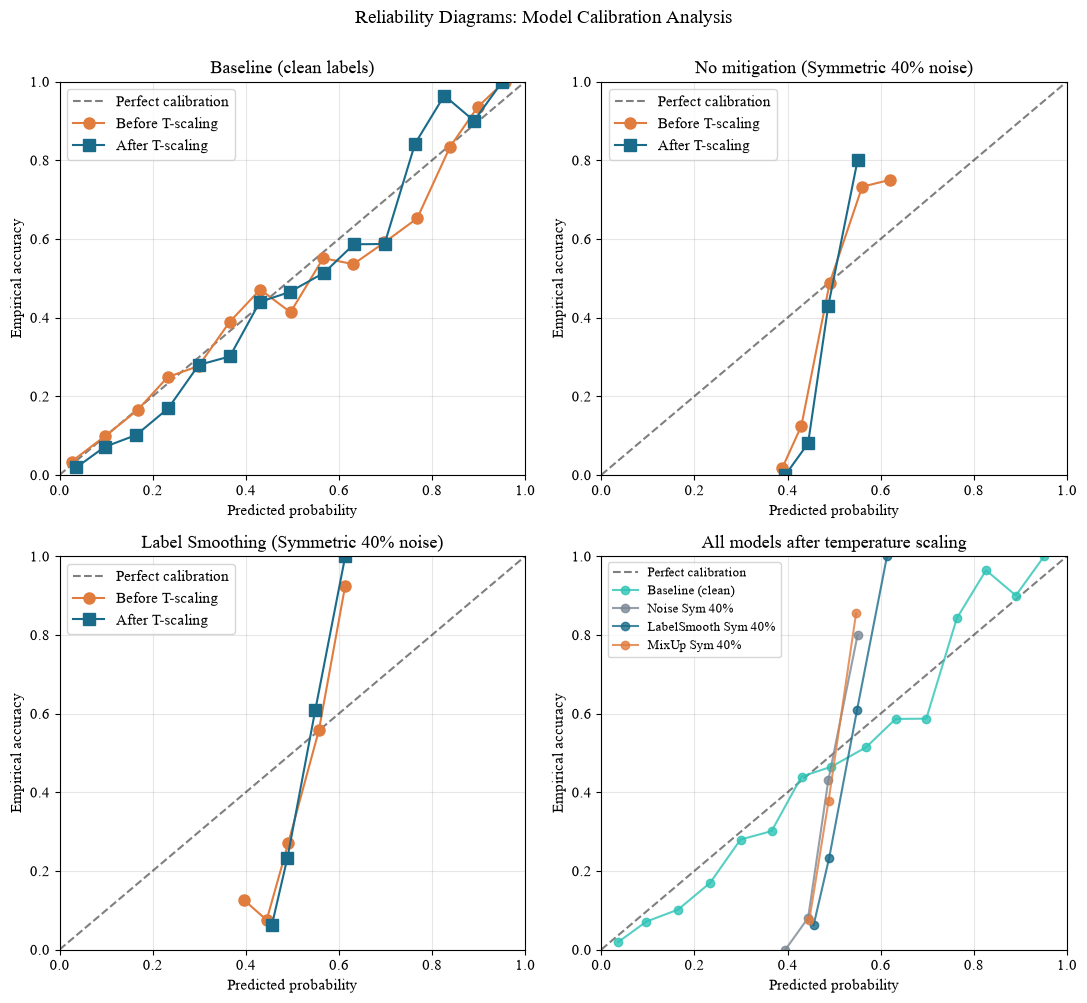

Saved: fig8_reliability_diagram.png/pdf


In [7]:
priority_models = [
    'Baseline (clean)',
    'Noise Sym 40%',
    'LabelSmooth Sym 40%',
    'MixUp Sym 40%',
]
available_priority = [m for m in priority_models if m in bin_data_cache]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

# Panel (0,0): Baseline before/after temperature scaling
if 'Baseline (clean)' in bin_data_cache:
    ax = axes[0, 0]
    bd = bin_data_cache['Baseline (clean)']
    bc, conf_b, acc_b, count_b = bd['before']
    bc, conf_a, acc_a, count_a = bd['after']
    mask_b = count_b > 0
    mask_a = count_a > 0
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', alpha=0.5)
    ax.plot(conf_b[mask_b], acc_b[mask_b], 'o-', color='#E07C3E', label='Before T-scaling', markersize=8)
    ax.plot(conf_a[mask_a], acc_a[mask_a], 's-', color='#1A6B8A', label='After T-scaling', markersize=8)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Empirical accuracy')
    ax.set_title('Baseline (clean labels)')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])

# Panel (0,1): Noise Sym 40% no-mit before/after
if 'Noise Sym 40%' in bin_data_cache:
    ax = axes[0, 1]
    bd = bin_data_cache['Noise Sym 40%']
    bc, conf_b, acc_b, count_b = bd['before']
    bc, conf_a, acc_a, count_a = bd['after']
    mask_b = count_b > 0
    mask_a = count_a > 0
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', alpha=0.5)
    ax.plot(conf_b[mask_b], acc_b[mask_b], 'o-', color='#E07C3E', label='Before T-scaling', markersize=8)
    ax.plot(conf_a[mask_a], acc_a[mask_a], 's-', color='#1A6B8A', label='After T-scaling', markersize=8)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Empirical accuracy')
    ax.set_title('No mitigation (Symmetric 40% noise)')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])

# Panel (1,0): Label smoothing before/after
if 'LabelSmooth Sym 40%' in bin_data_cache:
    ax = axes[1, 0]
    bd = bin_data_cache['LabelSmooth Sym 40%']
    bc, conf_b, acc_b, count_b = bd['before']
    bc, conf_a, acc_a, count_a = bd['after']
    mask_b = count_b > 0
    mask_a = count_a > 0
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', alpha=0.5)
    ax.plot(conf_b[mask_b], acc_b[mask_b], 'o-', color='#E07C3E', label='Before T-scaling', markersize=8)
    ax.plot(conf_a[mask_a], acc_a[mask_a], 's-', color='#1A6B8A', label='After T-scaling', markersize=8)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Empirical accuracy')
    ax.set_title('Label Smoothing (Symmetric 40% noise)')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])

# Panel (1,1): All methods AFTER T-scaling comparison
ax = axes[1, 1]
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', alpha=0.5)
colors_cmp = ['#2EC4B6', '#7B8794', '#1A6B8A', '#E07C3E', '#9B59B6', '#27AE60']
for i, name in enumerate(available_priority):
    if name not in bin_data_cache:
        continue
    bc, conf, acc, count = bin_data_cache[name]['after']
    mask = count > 0
    color = colors_cmp[i % len(colors_cmp)]
    ax.plot(conf[mask], acc[mask], 'o-', color=color, label=name, markersize=6, alpha=0.8)
ax.set_xlabel('Predicted probability')
ax.set_ylabel('Empirical accuracy')
ax.set_title('All models after temperature scaling')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1])

plt.suptitle('Reliability Diagrams: Model Calibration Analysis', fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig8_reliability_diagram.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig8_reliability_diagram.pdf'))
plt.show()
print('Saved: fig8_reliability_diagram.png/pdf')

## 6. Compare ECE Before and After Temperature Scaling

This bar chart provides a direct comparison of ECE before and after temperature scaling for all analyzed models.

Because lower ECE indicates better calibration, a lower post-scaling bar represents an improvement. The learned temperature for each model is also displayed to show how strongly the logits were adjusted.


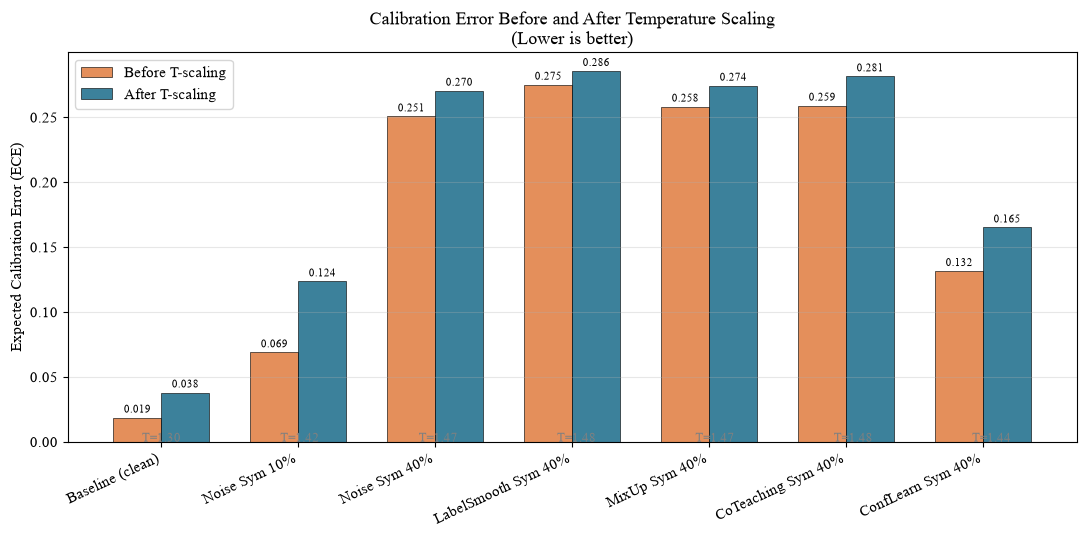

Saved: fig9_ece_comparison.png/pdf


In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(results_df))
width = 0.35

bars1 = ax.bar(x - width/2, results_df['ece_before'], width,
                color='#E07C3E', alpha=0.85, label='Before T-scaling',
                edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, results_df['ece_after'], width,
                color='#1A6B8A', alpha=0.85, label='After T-scaling',
                edgecolor='black', linewidth=0.5)

for bar, val in zip(bars1, results_df['ece_before']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.3f}',
            ha='center', va='bottom', fontsize=8)
for bar, val in zip(bars2, results_df['ece_after']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.3f}',
            ha='center', va='bottom', fontsize=8)

# Show T values above
for i, T in enumerate(results_df['T_optimal']):
    ax.annotate(f'T={T:.2f}', xy=(i, 0), xytext=(i, -0.008),
                ha='center', fontsize=9, color='gray',
                textcoords='offset points')

ax.set_xticks(x)
ax.set_xticklabels(results_df['model'], rotation=25, ha='right')
ax.set_ylabel('Expected Calibration Error (ECE)')
ax.set_title('Calibration Error Before and After Temperature Scaling\n(Lower is better)')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig9_ece_comparison.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig9_ece_comparison.pdf'))
plt.show()
print('Saved: fig9_ece_comparison.png/pdf')

## 7. Export Calibration Results

The calibration results are formatted as a LaTeX table.

For every analyzed model, the table reports the learned temperature, raw and temperature-scaled ECE, and raw and temperature-scaled Brier score. Lower ECE and Brier values indicate better calibration.


In [9]:
latex_lines = [
    '\\begin{table}[h]',
    '\\centering',
    '\\small',
    '\\caption{Model calibration analysis using temperature scaling. '
        'Lower ECE and Brier score indicate better calibration. '
        'Temperature $T$ > 1 indicates overconfidence corrected by softening predictions.}',
    '\\label{tab:calibration}',
    '\\begin{tabular}{lccccc}',
    '\\toprule',
    'Model & $T$ & ECE (raw) & ECE (T-scaled) & Brier (raw) & Brier (T-scaled) \\\\',
    '\\midrule',
]

for _, row in results_df.iterrows():
    line = f"{row['model']} & {row['T_optimal']:.3f} & {row['ece_before']:.4f} & {row['ece_after']:.4f} & {row['brier_before']:.4f} & {row['brier_after']:.4f} \\\\"
    latex_lines.append(line)

latex_lines.extend([
    '\\bottomrule',
    '\\end{tabular}',
    '\\end{table}',
])

latex_str = '\n'.join(latex_lines)
with open(os.path.join(CALIB_RESULTS_DIR, 'calibration_table.tex'), 'w') as f:
    f.write(latex_str)

print('LaTeX table saved to: calibration_table.tex\n')
print(latex_str)

LaTeX table saved to: calibration_table.tex

\begin{table}[h]
\centering
\small
\caption{Model calibration analysis using temperature scaling. Lower ECE and Brier score indicate better calibration. Temperature $T$ > 1 indicates overconfidence corrected by softening predictions.}
\label{tab:calibration}
\begin{tabular}{lccccc}
\toprule
Model & $T$ & ECE (raw) & ECE (T-scaled) & Brier (raw) & Brier (T-scaled) \\
\midrule
Baseline (clean) & 1.299 & 0.0186 & 0.0379 & 0.1166 & 0.1174 \\
Noise Sym 10% & 1.422 & 0.0689 & 0.1235 & 0.1155 & 0.1287 \\
Noise Sym 40% & 1.466 & 0.2506 & 0.2704 & 0.2039 & 0.2173 \\
LabelSmooth Sym 40% & 1.480 & 0.2751 & 0.2856 & 0.2251 & 0.2327 \\
MixUp Sym 40% & 1.469 & 0.2582 & 0.2743 & 0.2087 & 0.2208 \\
CoTeaching Sym 40% & 1.476 & 0.2590 & 0.2815 & 0.2197 & 0.2287 \\
ConfLearn Sym 40% & 1.445 & 0.1315 & 0.1651 & 0.1531 & 0.1633 \\
\bottomrule
\end{tabular}
\end{table}


## 8. Summarize the Key Findings

The final section reports the main calibration observations, including baseline calibration, average ECE reduction, temperature values across models, and the raw-calibration comparison between label smoothing and the no-mitigation model.

The interpretation of $T$ follows the notebook's convention: values above 1 soften predictions, values below 1 sharpen them, and values close to 1 require relatively little adjustment.


In [10]:
print('=' * 70)
print('CALIBRATION ANALYSIS - KEY FINDINGS')
print('=' * 70)

baseline_row = results_df[results_df['model'].str.contains('Baseline', case=False)]
if len(baseline_row) > 0:
    br = baseline_row.iloc[0]
    print(f'\n1. BASELINE CALIBRATION:')
    print(f'   ECE before T-scaling: {br["ece_before"]:.4f}')
    print(f'   ECE after T-scaling:  {br["ece_after"]:.4f}')
    print(f'   Optimal T:            {br["T_optimal"]:.3f}')
    if br['T_optimal'] > 1.1:
        print(f'   -> Model is OVERCONFIDENT (T > 1 needed to soften predictions)')
    elif br['T_optimal'] < 0.9:
        print(f'   -> Model is UNDERCONFIDENT (T < 1 needed to sharpen predictions)')
    else:
        print(f'   -> Model is reasonably calibrated already')

print(f'\n2. TEMPERATURE SCALING EFFECT:')
avg_reduction = ((results_df['ece_before'] - results_df['ece_after']) * 100).mean()
print(f'   Average ECE reduction: {avg_reduction:.2f} percentage points')
print(f'   T-scaling reduced ECE for {(results_df["ece_after"] < results_df["ece_before"]).sum()}/{len(results_df)} models')

print(f'\n3. TEMPERATURE VALUES ACROSS MODELS:')
for _, row in results_df.iterrows():
    interp = 'overconfident' if row['T_optimal'] > 1.1 else ('underconfident' if row['T_optimal'] < 0.9 else 'well-calibrated')
    print(f'   {row["model"]:<30}: T={row["T_optimal"]:.3f} ({interp})')

ls_row = results_df[results_df['model'].str.contains('LabelSmooth', case=False)]
nomit_row = results_df[results_df['model'].str.contains('Noise Sym 40', case=False)]

if len(ls_row) > 0 and len(nomit_row) > 0:
    ls = ls_row.iloc[0]
    nm = nomit_row.iloc[0]
    print(f'\n4. LABEL SMOOTHING EFFECT ON CALIBRATION:')
    print(f'   No mitigation:   T={nm["T_optimal"]:.3f}, ECE={nm["ece_before"]:.4f}')
    print(f'   Label smoothing: T={ls["T_optimal"]:.3f}, ECE={ls["ece_before"]:.4f}')
    if abs(ls['T_optimal'] - 1.0) < abs(nm['T_optimal'] - 1.0):
        print(f'   -> Label smoothing produced better-calibrated raw predictions')
    if ls['ece_before'] < nm['ece_before']:
        print(f'   -> Label smoothing improved raw ECE by {(nm["ece_before"]-ls["ece_before"])*100:.2f}pp')

print('\n' + '=' * 70)
print(f'Models analyzed: {len(results_df)}')
print(f'Figures saved to: {FIGURES_DIR}')
print(f'Tables/CSV saved to: {CALIB_RESULTS_DIR}')
print('=' * 70)

CALIBRATION ANALYSIS - KEY FINDINGS

1. BASELINE CALIBRATION:
   ECE before T-scaling: 0.0186
   ECE after T-scaling:  0.0379
   Optimal T:            1.299
   -> Model is OVERCONFIDENT (T > 1 needed to soften predictions)

2. TEMPERATURE SCALING EFFECT:
   Average ECE reduction: -2.52 percentage points
   T-scaling reduced ECE for 0/7 models

3. TEMPERATURE VALUES ACROSS MODELS:
   Baseline (clean)              : T=1.299 (overconfident)
   Noise Sym 10%                 : T=1.422 (overconfident)
   Noise Sym 40%                 : T=1.466 (overconfident)
   LabelSmooth Sym 40%           : T=1.480 (overconfident)
   MixUp Sym 40%                 : T=1.469 (overconfident)
   CoTeaching Sym 40%            : T=1.476 (overconfident)
   ConfLearn Sym 40%             : T=1.445 (overconfident)

4. LABEL SMOOTHING EFFECT ON CALIBRATION:
   No mitigation:   T=1.466, ECE=0.2506
   Label smoothing: T=1.480, ECE=0.2751

Models analyzed: 7
Figures saved to: ..\results\figures
Tables/CSV saved to: ..\